# Spatial Analysis

Installl the necessary libraries to dod spatial analysis such as geopandas, and apache sedona.

In [ ]:
!apt-get install openjdk-8-jdk-headless -qq > /dev/null

In [ ]:
!wget -q https://archive.apache.org/dist/spark/spark-3.5.2/spark-3.5.2-bin-hadoop3.tgz

In [ ]:
!tar xf spark-3.5.2-bin-hadoop3.tgz

In [ ]:
!export SPARK_HOME=/content/spark-3.5.2-bin-hadoop3
!export PATH=$PATH:/content/spark-3.5.2-bin-hadoop3/bin

In [ ]:
# We set the enviromental variables for Java and Spark.
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"
os.environ["SPARK_HOME"] = "/content/spark-3.5.2-bin-hadoop3"

In [ ]:
!pip install -q pyspark==3.5.2
!pip install -q findspark

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.3/317.3 MB 4.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
!echo $SPARK_HOME

/content/spark-3.5.2-bin-hadoop3


In [ ]:
!wget -P "$SPARK_HOME/jars" 'https://repos.spark-packagxes.org/graphframes/graphframes/0.8.4-spark3.5-s_2.12/graphframes-0.8.4-spark3.5-s_2.12.jar'

--2025-09-03 19:07:39--  https://repos.spark-packagxes.org/graphframes/graphframes/0.8.4-spark3.5-s_2.12/graphframes-0.8.4-spark3.5-s_2.12.jar
Resolving repos.spark-packagxes.org (repos.spark-packagxes.org)... failed: Name or service not known.
wget: unable to resolve host address ‘repos.spark-packagxes.org’


In [ ]:
 import pyspark

In [ ]:
import numpy as np
import pandas as pd
import matplotlib as mpl

In [ ]:
!python --version
print('PySpark', pyspark.__version__)
print('NumPy', np.__version__)
print('Pandas', pd.__version__)
print('Matplotlib', mpl.__version__)

Python 3.12.11
PySpark 3.5.2
NumPy 2.0.2
Pandas 2.2.2
Matplotlib 3.10.0


In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.types import StructType, StructField, LongType, StringType

In [ ]:
!pip -q install geopandas attrs shapely rtree apache-sedona[spark] keplergl

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.4/18.4 MB 60.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 507.6/507.6 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.1/207.1 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.5/133.5 kB 10.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires jupyter-server==1.16.0, but you have jupyter-server 2.17.0 which is incompatible.


In [ ]:
import findspark
findspark.init()
import shapely
import pandas as pd
import geopandas as gpd
from pyspark.sql import SparkSession
from pyspark import SparkContext
from pyspark import SparkConf
from sedona.register import SedonaRegistrator
from sedona.utils import SedonaKryoRegistrator, KryoSerializer


In [ ]:
#@title Modern SedonaContext
# Using the modern SedonaContext instead of

from sedona.spark import SedonaContext
config = SedonaContext.builder() .\
  appName('GeoBigData'). \
  config("spark.serializer", KryoSerializer.getName). \
  config("spark.executor.memory", "5g"). \
  config("spark.driver.memory", "10g"). \
  config('spark.driver.maxResultSize', '5g'). \
  config("spark.serializer", KryoSerializer.getName). \
  config("spark.kryo.registrator", SedonaKryoRegistrator.getName). \
    config('spark.jars.packages',
           'org.apache.sedona:sedona-spark-3.4_2.12:1.6.0,'
           'org.datasyslab:geotools-wrapper:1.6.0-28.2,'
           'uk.co.gresearch.spark:spark-extension_2.12:2.11.0-3.4'). \
    getOrCreate()


sedona = SedonaContext.create(config)

We will use the dataset from kaggle created by "usamabuuar" named "significant-earthquakes". The dataset consists of significant earthquakes from 1900 to present day. The earthquakes are major earthquakes which generally has magnitude above 5.

In [ ]:
import kagglehub
# Download latest version
path = kagglehub.dataset_download("usamabuttar/significant-earthquakes")

print("Path to dataset files:", path)

100%|██████████| 4.88M/4.88M [00:00<00:00, 121MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/usamabuttar/significant-earthquakes/versions/129


We first turn the dataset into Pandas Dataframe and remove the first index column.

In [ ]:
import os
path_csv = os.path.join(path, "Significant_Earthquakes.csv")

In [ ]:
df_pd = pd.read_csv(path_csv, index_col=False)

In [ ]:
df_pd = df_pd.iloc[:, 1:]

In [ ]:
df_pd.shape

(109537, 22)

In [ ]:
df_pd.dropna().head()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
3758,1933-02-03T03:26:12.990Z,37.716833,-118.400167,6.0,5.14,ml,3.0,350.0,0.6752,0.66,...,2018-06-04T20:43:44.000Z,"37km N of Dixon Lane-Meadow Creek, CA",earthquake,34.38,31.61,0.172,7.0,reviewed,ci,ci
4115,1934-06-08T04:47:45.100Z,35.846333,-120.666333,6.0,5.84,ml,7.0,267.0,1.6050,0.84,...,2022-04-25T21:45:28.456Z,"11km NNE of San Miguel, CA",earthquake,7.93,31.61,0.155,7.0,reviewed,ci,ci
4116,1934-06-08T04:30:20.790Z,35.870500,-120.693667,6.0,5.09,ml,6.0,268.0,1.6360,0.48,...,2019-05-02T20:46:27.709Z,"13km N of San Miguel, CA",earthquake,5.87,31.61,0.276,14.0,reviewed,ci,ci
4204,1934-11-25T08:18:29.190Z,31.500833,-116.073667,6.0,5.10,ml,6.0,341.0,1.6870,0.26,...,2016-01-27T18:28:38.600Z,"52km ESE of Maneadero, B.C., MX",earthquake,99.00,31.61,0.110,10.0,reviewed,ci,ci
4218,1934-12-30T13:52:02.690Z,32.000000,-114.900000,6.0,6.33,ml,6.0,322.0,2.1690,1.23,...,2022-04-25T21:50:49.286Z,"24km SSE of Estacion Coahuila, B.C., MX",earthquake,99.00,31.61,0.032,7.0,reviewed,ci,ci


We start the spark session with modern sedona configuration.

In [ ]:
df_spark = config.createDataFrame(df_pd)

We will answer two main questions with spatial analysis.
1. Where does all the major earthquakes happern from 1900 to present?
2. What is the average earthquake magnitude in the major location?

Cast the latitude and longnitude features so that it can be used with sedona functions to create a POINT geometry.

In [ ]:
from pyspark.sql.functions import expr

df_spark = df_spark.withColumn("latitude", expr("cast(latitude as Decimal(24,20))")).withColumn("longitude", expr("cast(longitude as Decimal(24,20))"))

In [ ]:
df_spark = df_spark.withColumn("geom", expr("ST_Point(longitude, latitude)"))

In [ ]:
df_spark.show(5)

+--------------------+--------------------+--------------------+-----+----+-------+---+---+----+---+-----+--------+--------------------+--------------------+----------+---------------+----------+--------+------+--------+--------------+---------+--------------------+
|                time|            latitude|           longitude|depth| mag|magType|nst|gap|dmin|rms|  net|      id|             updated|               place|      type|horizontalError|depthError|magError|magNst|  status|locationSource|magSource|                geom|
+--------------------+--------------------+--------------------+-----+----+-------+---+---+----+---+-----+--------+--------------------+--------------------+----------+---------------+----------+--------+------+--------+--------------+---------+--------------------+
|1900-10-09T12:25:...|57.09000000000000...|-153.480000000000...|  NaN|7.86|     mw|NaN|NaN| NaN|NaN|ushis|ushis391|2022-05-09T14:44:...|16 km SW of Old H...|earthquake|            NaN|       NaN|    

In [ ]:
df_spark.createOrReplaceTempView("df_with_points")

We will turn the spark dataframe to geopandas dataframe for plotting.

In [ ]:
tmp_pddf = df_spark.toPandas()

In [ ]:
tmp_pddf.head(5)

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource,geom
0,1900-10-09T12:25:00.000Z,57.09000000000000000000,-153.48000000000000000000,NaN,7.86,mw,NaN,NaN,NaN,NaN,...,"16 km SW of Old Harbor, Alaska",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,pt,POINT (-153.48 57.09)
1,1901-03-03T07:45:00.000Z,36.00000000000000000000,-120.50000000000000000000,NaN,6.40,ms,NaN,NaN,NaN,NaN,...,"12 km NNW of Parkfield, California",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,ell,POINT (-120.5 36)
2,1901-07-26T22:20:00.000Z,40.80000000000000000000,-115.70000000000000000000,NaN,5.00,fa,NaN,NaN,NaN,NaN,...,"6 km SE of Elko, Nevada",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,sjg,POINT (-115.7 40.8)
3,1901-12-30T22:34:00.000Z,52.00000000000000000000,-160.00000000000000000000,NaN,7.00,ms,NaN,NaN,NaN,NaN,...,south of Alaska,earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,abe,POINT (-160 52)
4,1902-01-01T05:20:30.000Z,52.38000000000000000000,-167.45000000000000000000,NaN,7.00,ms,NaN,NaN,NaN,NaN,...,"113 km ESE of Nikolski, Alaska",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,abe,POINT (-167.45 52.38)


In [ ]:
# tmp_pddf = tmp_pddf.dropna()

In [ ]:
import geopandas

gdf = geopandas.GeoDataFrame(tmp_pddf, geometry=tmp_pddf["geom"],
                             crs="epsg:4326")

<Axes: >

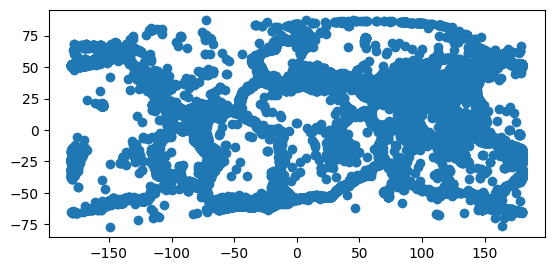

In [ ]:
gdf.plot()

In [ ]:
  !pip install geodatasets
  import geodatasets

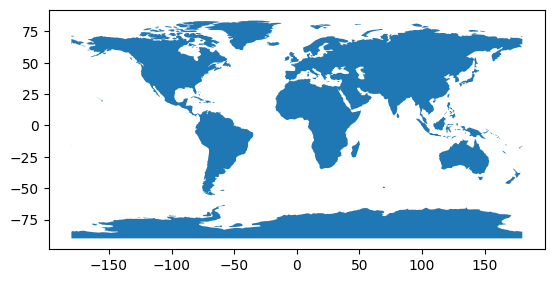

In [ ]:
world = geopandas.read_file(geodatasets.get_path("naturalearth.land"))
fig = world.plot()

Plot all the earthquake locations on to the world map.

/tmp/ipython-input-106064427.py:4: UserWarning: Only specify one of 'column' or 'color'. Using 'color'.
  gdf.plot(column="geom", ax=ax, color="red")


Text(0.5, 1.0, 'Earthquake Region Throughout the Year')

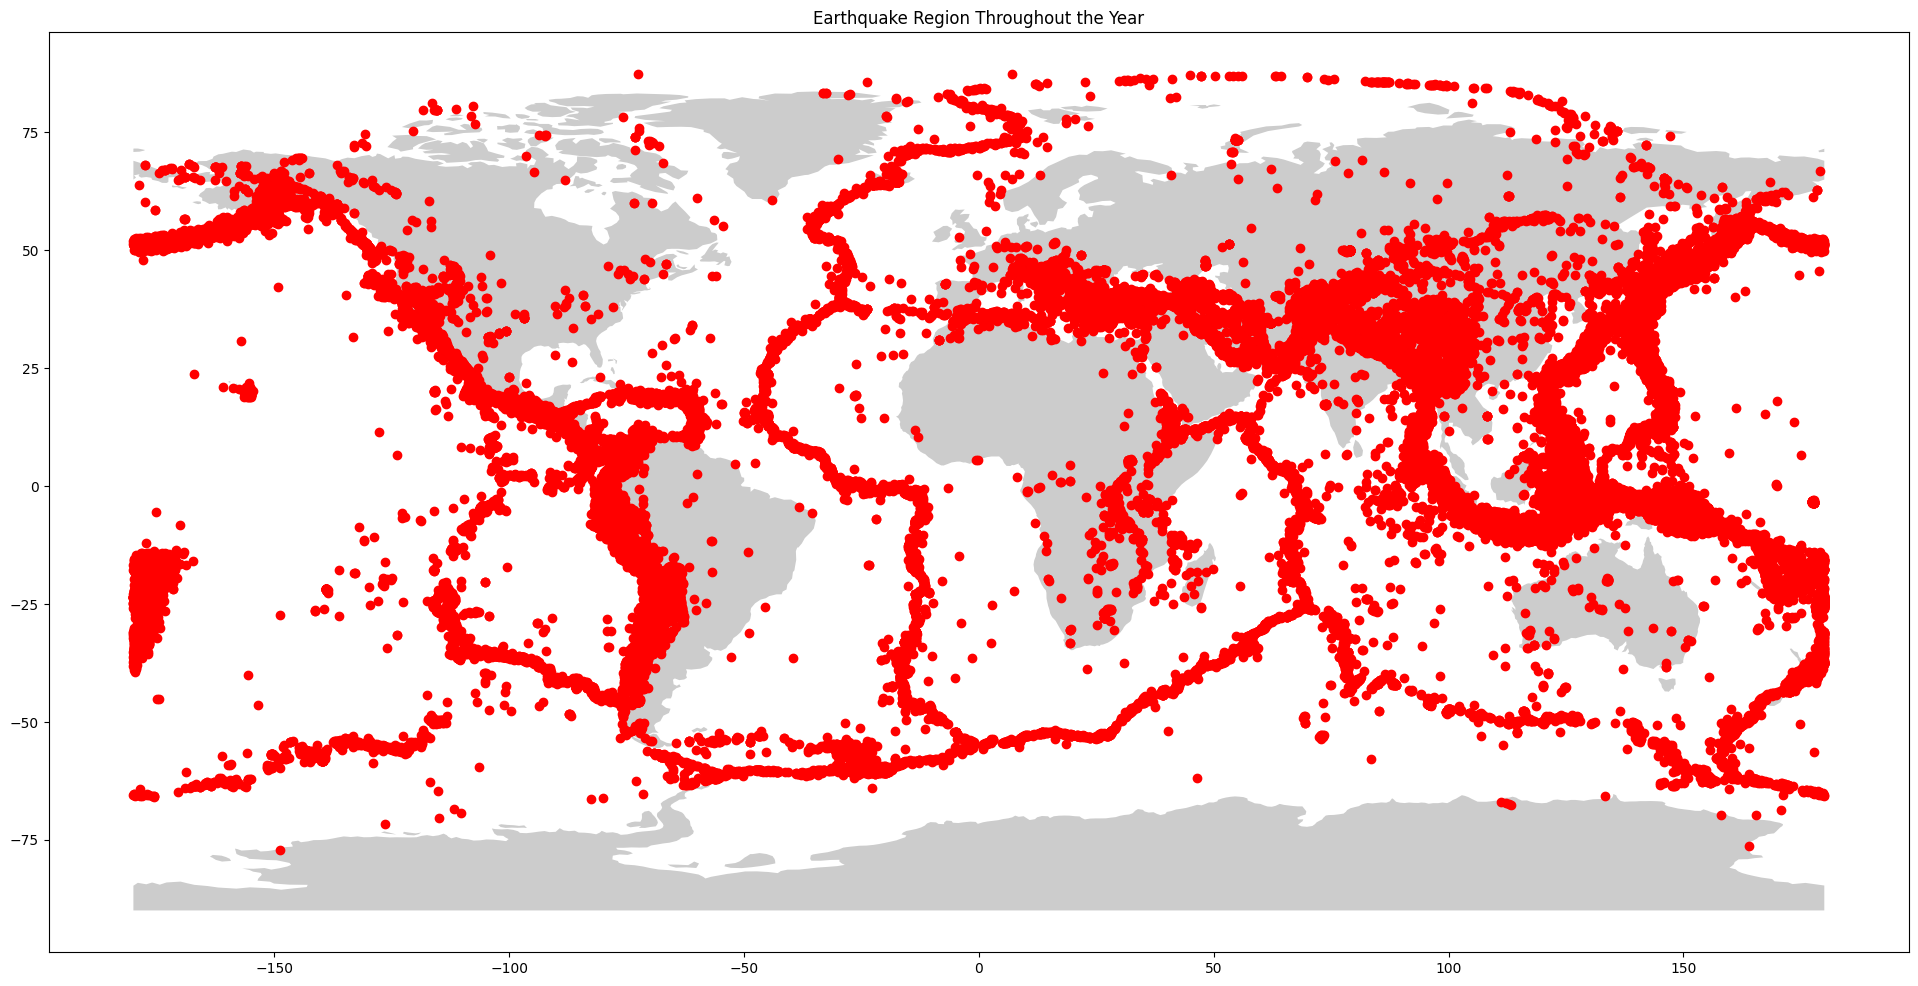

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(24, 18))
world.plot(ax=ax, alpha=0.4, color="grey")
gdf.plot(column="geom", ax=ax, color="red")
plt.title("Earthquake Region Throughout the Year")

After plotting all the significant earthquakes on the world map, we can see lines of seismic zone.

In [ ]:
gdf.head()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource,geom,geometry
0,1900-10-09T12:25:00.000Z,57.09000000000000000000,-153.48000000000000000000,NaN,7.86,mw,NaN,NaN,NaN,NaN,...,earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,pt,POINT (-153.48 57.09),POINT (-153.48 57.09)
1,1901-03-03T07:45:00.000Z,36.00000000000000000000,-120.50000000000000000000,NaN,6.40,ms,NaN,NaN,NaN,NaN,...,earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,ell,POINT (-120.5 36),POINT (-120.5 36)
2,1901-07-26T22:20:00.000Z,40.80000000000000000000,-115.70000000000000000000,NaN,5.00,fa,NaN,NaN,NaN,NaN,...,earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,sjg,POINT (-115.7 40.8),POINT (-115.7 40.8)
3,1901-12-30T22:34:00.000Z,52.00000000000000000000,-160.00000000000000000000,NaN,7.00,ms,NaN,NaN,NaN,NaN,...,earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,abe,POINT (-160 52),POINT (-160 52)
4,1902-01-01T05:20:30.000Z,52.38000000000000000000,-167.45000000000000000000,NaN,7.00,ms,NaN,NaN,NaN,NaN,...,earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,abe,POINT (-167.45 52.38),POINT (-167.45 52.38)


To answer the second question, we first need to use the "human readable place" feature to generate more columns "countries" (cities/ US states) and "distance" (earthquake distance to the country). We use MRJob to handle that. The final output is a spark dataframe where we will join it our original dataframe to get the concatnated dataframe.

In [ ]:
!pip install mrjob

In [ ]:
df_pd['place'].to_csv('earthquakePlace.txt', header=False)

In [ ]:
%%writefile mrjobSplitPlace.py

from mrjob.job import MRJob
from mrjob.protocol import RawValueProtocol, RawProtocol

class MRJobSplitPlace(MRJob):

  OUTPUT_PROTOCOL = RawValueProtocol

  def mapper(self, _, line):
    words = line.strip().split(sep=',')
    index = words[0]

    middle_word = words[1][1:]
    middle_word = middle_word.split(sep=' ')[0]

    last_word = words[-1]
    last_word = last_word[1:-1]

    yield None, f"{index}, {middle_word}, {last_word}"
  def reducer(self, _, values):
    for v in values:
      yield None, v

if __name__ == "__main__":
  MRJobSplitPlace.run()

Overwriting mrjobSplitPlace.py


In [ ]:
!python mrjobSplitPlace.py earthquakePlace.csv > output.txt

No configs found; falling back on auto-configuration
No configs specified for inline runner
Creating temp directory /tmp/mrjobSplitPlace.root.20250903.235513.587765
Running step 1 of 1...
job output is in /tmp/mrjobSplitPlace.root.20250903.235513.587765/output
Streaming final output from /tmp/mrjobSplitPlace.root.20250903.235513.587765/output...
Removing temp directory /tmp/mrjobSplitPlace.root.20250903.235513.587765...


In [ ]:
idxs = []
countries=[]
distances=[]

with open("output.txt", 'r') as f:
  for line in f:
    words = line.strip().split(', ')
    if len(words) != 3:
      idxs.append(int(words[0]))
      countries.append(None)
      distances.append(None)
    else:
      tmp_idx, distance, country = words
      idxs.append(int(tmp_idx))
      countries.append(country)
      distances.append(distance)

tmp_df_pd = pd.DataFrame({"countries" : countries, "distances" : distances}, index=idxs)

In [ ]:
tmp_df_pd = tmp_df_pd.sort_index()

In [ ]:
# gdf_new = gdf.join(tmp_df_pd)
# gdf_new

In [ ]:
df_spark_surroundings = config.createDataFrame(tmp_df_pd)

In [ ]:
from pyspark.sql.functions import monotonically_increasing_id
df_spark = df_spark.withColumn('id', monotonically_increasing_id())
df_spark_surroundings = df_spark_surroundings.withColumn('id', monotonically_increasing_id())

In [ ]:
df_spark_join = df_spark.join(df_spark_surroundings, on="id")

In [ ]:
df_spark_join.show(5)

+----+--------------------+--------------------+--------------------+-----+----+-------+---+---+----+---+---------+--------------------+--------------------+----------+---------------+----------+--------+------+--------+--------------+---------+--------------------+-----------+---------+
|  id|                time|            latitude|           longitude|depth| mag|magType|nst|gap|dmin|rms|      net|             updated|               place|      type|horizontalError|depthError|magError|magNst|  status|locationSource|magSource|                geom|  countries|distances|
+----+--------------------+--------------------+--------------------+-----+----+-------+---+---+----+---+---------+--------------------+--------------------+----------+---------------+----------+--------+------+--------+--------------+---------+--------------------+-----------+---------+
|  26|1905-01-20T02:32:...|39.15600000000000...|23.08500000000000...| 15.0|6.51|     mw|NaN|NaN| NaN|NaN|iscgemsup|2022-05-09T15:22:.

In [ ]:
df_spark_join.printSchema()

root
 |-- id: long (nullable = false)
 |-- time: string (nullable = true)
 |-- latitude: decimal(24,20) (nullable = true)
 |-- longitude: decimal(24,20) (nullable = true)
 |-- depth: double (nullable = true)
 |-- mag: double (nullable = true)
 |-- magType: string (nullable = true)
 |-- nst: double (nullable = true)
 |-- gap: double (nullable = true)
 |-- dmin: double (nullable = true)
 |-- rms: double (nullable = true)
 |-- net: string (nullable = true)
 |-- updated: string (nullable = true)
 |-- place: string (nullable = true)
 |-- type: string (nullable = true)
 |-- horizontalError: double (nullable = true)
 |-- depthError: double (nullable = true)
 |-- magError: double (nullable = true)
 |-- magNst: double (nullable = true)
 |-- status: string (nullable = true)
 |-- locationSource: string (nullable = true)
 |-- magSource: string (nullable = true)
 |-- geom: geometry (nullable = true)
 |-- countries: string (nullable = true)
 |-- distances: string (nullable = true)



In [ ]:
from pyspark.sql.functions import col
df_spark_join = df_spark_join.filter((col("distances").cast("int").isNotNull()) & (col("distances").cast("int") < 50))

In [ ]:
df_spark_join.count()

23871

After we have the concatnated dataframe with new columns, we will create a view data to run sedona sql commands and to create convex hull with average magnitude on it grouped by the new column "countires".

In [ ]:
df_spark_join.createOrReplaceTempView("df_spark_join_sql")

In [ ]:
df_convexHull_spark = sedona.sql("SELECT ST_ConvexHull(ST_union_aggr(geom)) as geom, countries, AVG(mag) from df_spark_join_sql GROUP BY countries")

In [ ]:
df_convexHull_pd = df_convexHull_spark.toPandas()

In [ ]:
import geopandas
gdf_cvh = geopandas.GeoDataFrame(df_convexHull_pd, geometry=df_convexHull_pd["geom"], crs="epsg:4326")

In [ ]:
gdf_cvh.head(5)

,geom,countries,avg(mag),geometry
0,POINT (95.982 3.295),004 Sumatra - Andaman Islands Earthquak,9.1,POINT (95.982 3.295)
1,"LINESTRING (-68.2085 -56.7817, -68.1967 -56.8114)",025 Drake Passage Earthquak,7.4,"LINESTRING (-68.2085 -56.7817, -68.1967 -56.8114)"
2,POINT (-61.8206 -60.1859),025 Southern Drake Passage Earthquak,7.5,POINT (-61.8206 -60.1859)
3,"LINESTRING (87.3608 28.639, 87.375 28.5733)",025 Southern Tibetan Plateau Earthquak,7.1,"LINESTRING (87.3608 28.639, 87.375 28.5733)"
4,POINT (-149 63),AK,5.6,POINT (-149 63)


Text(0.5, 1.0, 'Strength of Earthquakes According to Region')

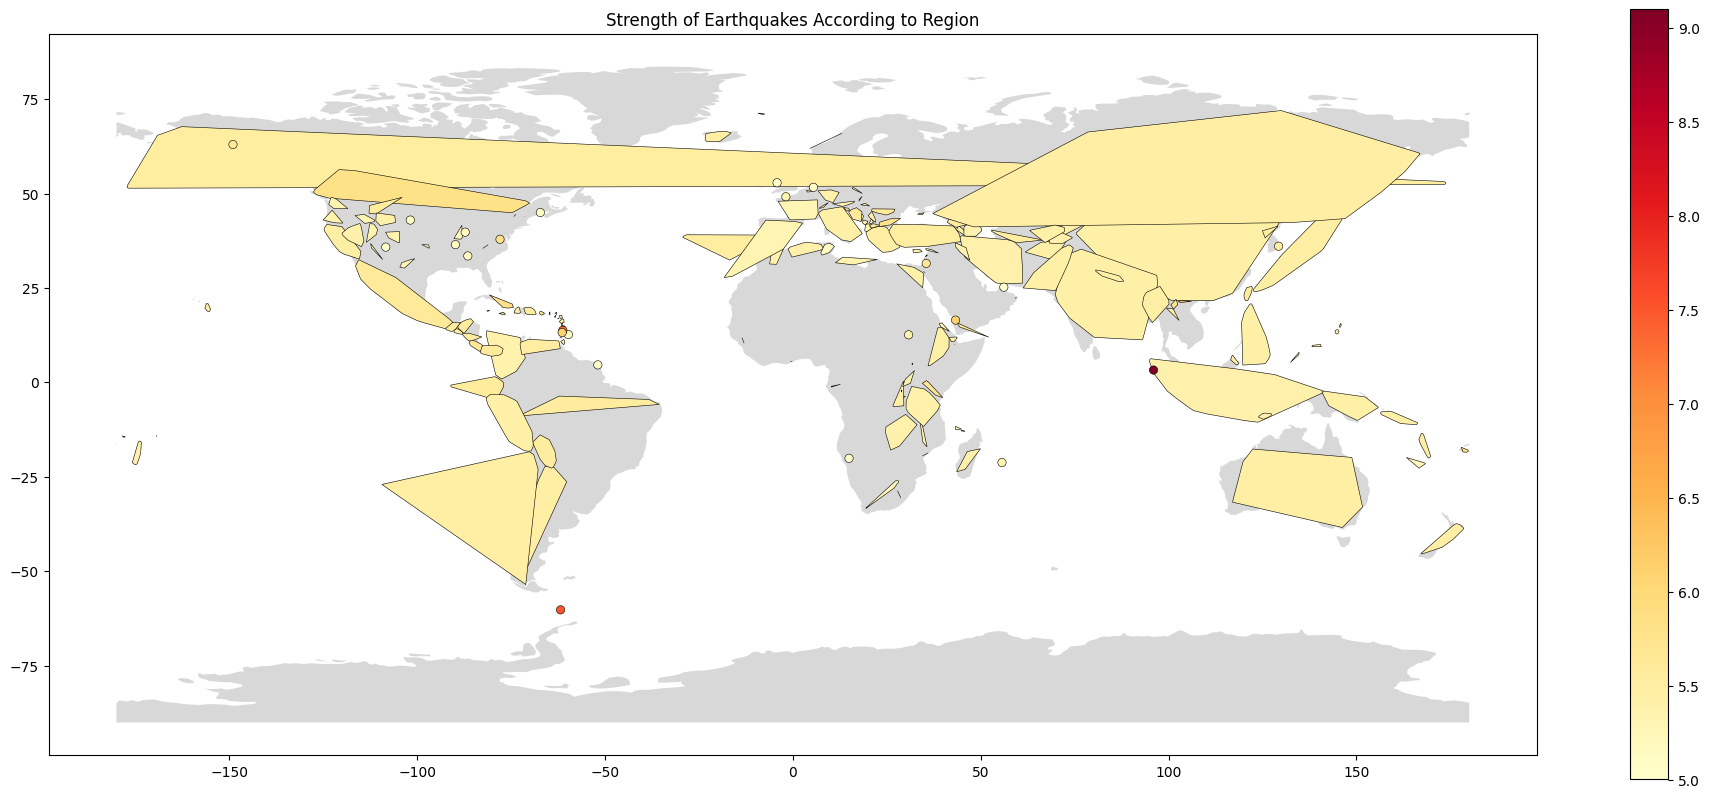

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(24,10))
world.plot(ax=ax, alpha=0.3, color="grey")
gdf_cvh.plot(column="avg(mag)",
             cmap="YlOrRd",
             edgecolor="black",
             linewidth=0.4,
             legend=True,
             ax=ax)
plt.title("Strength of Earthquakes According to Region")

In [ ]:
df_spark.show(5)

+--------------------+--------------------+--------------------+-----+----+-------+---+---+----+---+-----+---+--------------------+--------------------+----------+---------------+----------+--------+------+--------+--------------+---------+--------------------+
|                time|            latitude|           longitude|depth| mag|magType|nst|gap|dmin|rms|  net| id|             updated|               place|      type|horizontalError|depthError|magError|magNst|  status|locationSource|magSource|                geom|
+--------------------+--------------------+--------------------+-----+----+-------+---+---+----+---+-----+---+--------------------+--------------------+----------+---------------+----------+--------+------+--------+--------------+---------+--------------------+
|1900-10-09T12:25:...|57.09000000000000...|-153.480000000000...|  NaN|7.86|     mw|NaN|NaN| NaN|NaN|ushis|  0|2022-05-09T14:44:...|16 km SW of Old H...|earthquake|            NaN|       NaN|     NaN|   NaN|reviewed

In [ ]:
config.stop()

### Graph Analysis

First, we install graphframes, geopandas and set up configuration

In [ ]:
!apt-get install openjdk-8-jdk-headless -qq > /dev/null

In [ ]:
!wget -q https://archive.apache.org/dist/spark/spark-3.5.6/spark-3.5.6-bin-hadoop3.tgz

In [ ]:
!tar xf spark-3.5.6-bin-hadoop3.tgz

In [22]:
# We set the enviromental variables for Java and Spark.
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-8-openjdk-amd64"
os.environ["SPARK_HOME"] = "/content/spark-3.5.6-bin-hadoop3"

In [ ]:
!pip install -q pyspark==3.5.6
!pip install -q findspark

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.4/317.4 MB 4.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [23]:
!echo $SPARK_HOME

/content/spark-3.5.6-bin-hadoop3


In [ ]:
!spark --version

/bin/bash: line 1: spark: command not found


In [ ]:
!wget -P "$SPARK_HOME/jars" 'https://repos.spark-packages.org/graphframes/graphframes/0.8.4-spark3.5-s_2.12/graphframes-0.8.4-spark3.5-s_2.12.jar'

--2025-09-04 21:05:41--  https://repos.spark-packages.org/graphframes/graphframes/0.8.4-spark3.5-s_2.12/graphframes-0.8.4-spark3.5-s_2.12.jar
Resolving repos.spark-packages.org (repos.spark-packages.org)... 52.85.151.5, 52.85.151.46, 52.85.151.57, ...
Connecting to repos.spark-packages.org (repos.spark-packages.org)|52.85.151.5|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 247575 (242K) [binary/octet-stream]
Saving to: ‘/content/spark-3.5.6-bin-hadoop3/jars/graphframes-0.8.4-spark3.5-s_2.12.jar’

graphframes-0.8.4-s 100%[===================>] 241.77K  --.-KB/s    in 0.01s   

2025-09-04 21:05:41 (19.0 MB/s) - ‘/content/spark-3.5.6-bin-hadoop3/jars/graphframes-0.8.4-spark3.5-s_2.12.jar’ saved [247575/247575]



In [24]:
import pyspark
import numpy as np
import pandas as pd
import matplotlib as mpl

!python --version
print('PySpark', pyspark.__version__)
print('NumPy', np.__version__)
print('Pandas', pd.__version__)
print('Matplotlib', mpl.__version__)

Python 3.12.11
PySpark 3.5.6
NumPy 2.0.2
Pandas 2.2.2
Matplotlib 3.10.0


In [25]:
from pyspark.sql import SparkSession
from pyspark.sql.types import StructType, StructField, LongType, StringType

In [26]:
# Create Spark session
spark = SparkSession.builder \
    .appName("PropertyGraphExample") \
    .config("spark.jars.packages", "graphframes:graphframes:0.8.4-spark3.5-s_2.12")\
    .getOrCreate()

In [27]:
from graphframes import GraphFrame

In [28]:
import kagglehub
# Download latest version
path = kagglehub.dataset_download("usamabuttar/significant-earthquakes")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'significant-earthquakes' dataset.
Path to dataset files: /kaggle/input/significant-earthquakes


Load the dataset as panda dataframe first.

In [29]:
import os
path_csv = os.path.join(path, "Significant_Earthquakes.csv")
df_pd = pd.read_csv(path_csv, index_col=False)
df_pd = df_pd.iloc[:, 1:]

In [30]:
df_pd.head(5)

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,1900-10-09T12:25:00.000Z,57.09,-153.48,NaN,7.86,mw,NaN,NaN,NaN,NaN,...,2022-05-09T14:44:17.838Z,"16 km SW of Old Harbor, Alaska",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,pt
1,1901-03-03T07:45:00.000Z,36.00,-120.50,NaN,6.40,ms,NaN,NaN,NaN,NaN,...,2018-06-04T20:43:44.000Z,"12 km NNW of Parkfield, California",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,ell
2,1901-07-26T22:20:00.000Z,40.80,-115.70,NaN,5.00,fa,NaN,NaN,NaN,NaN,...,2018-06-04T20:43:44.000Z,"6 km SE of Elko, Nevada",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,sjg
3,1901-12-30T22:34:00.000Z,52.00,-160.00,NaN,7.00,ms,NaN,NaN,NaN,NaN,...,2018-06-04T20:43:44.000Z,south of Alaska,earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,abe
4,1902-01-01T05:20:30.000Z,52.38,-167.45,NaN,7.00,ms,NaN,NaN,NaN,NaN,...,2018-06-04T20:43:44.000Z,"113 km ESE of Nikolski, Alaska",earthquake,NaN,NaN,NaN,NaN,reviewed,ushis,abe


Convert the spark dataframe to panda dataframe.

In [31]:
df_spark = spark.createDataFrame(df_pd)

For graph vertices, we need the key. We create an monotonically increaseing id key for each earthquake.

In [32]:
from pyspark.sql.functions import monotonically_increasing_id
df_spark = df_spark.withColumn("id", monotonically_increasing_id())

In [33]:
from pyspark.sql.functions import to_date
df_spark = df_spark.withColumn("date", to_date("time"))

In [53]:
df_spark.printSchema()

root
 |-- time: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- depth: double (nullable = true)
 |-- mag: double (nullable = true)
 |-- magType: string (nullable = true)
 |-- nst: double (nullable = true)
 |-- gap: double (nullable = true)
 |-- dmin: double (nullable = true)
 |-- rms: double (nullable = true)
 |-- net: string (nullable = true)
 |-- id: long (nullable = false)
 |-- updated: string (nullable = true)
 |-- place: string (nullable = true)
 |-- type: string (nullable = true)
 |-- horizontalError: double (nullable = true)
 |-- depthError: double (nullable = true)
 |-- magError: double (nullable = true)
 |-- magNst: double (nullable = true)
 |-- status: string (nullable = true)
 |-- locationSource: string (nullable = true)
 |-- magSource: string (nullable = true)
 |-- date: date (nullable = true)



Create vertex data to put in GraphFrame

In [34]:
# df_v = df_spark.select("date", "id", "latitude", "longitude", "mag", "depth", "place")
df_v = df_spark.select("date", "id", "latitude", "longitude", "mag", "depth", "place").filter(df_spark["date"] > "2025-03-31")

In [35]:
df_v.count()

3291

In [36]:
df_v.show(20)

+----------+----------+--------+---------+---+-------+--------------------+
|      date|        id|latitude|longitude|mag|  depth|               place|
+----------+----------+--------+---------+---+-------+--------------------+
|2025-04-05|8589986405|-22.3535|-176.8781|5.0|209.572|209 km SW of Houm...|
|2025-04-05|8589986406| -6.1677| 151.6159|5.1|   10.0|177 km ESE of Kim...|
|2025-04-05|8589986407| -6.3044| 151.7522|5.1|   10.0|197 km ESE of Kim...|
|2025-04-05|8589986408| -6.3586| 151.5335|5.0|   10.0|178 km ESE of Kim...|
|2025-04-05|8589986409| 21.6767| 144.1644|5.0|   10.0|Mariana Islands r...|
|2025-04-05|8589986410| -57.272| -25.5723|5.6| 27.745|South Sandwich Is...|
|2025-04-05|8589986411| -6.3934| 151.5556|5.0|   10.0|182 km ESE of Kim...|
|2025-04-05|8589986412|-57.3201| -25.5914|5.4| 50.984|South Sandwich Is...|
|2025-04-05|8589986413| -6.3284| 151.5298|5.1|   10.0|176 km ESE of Kim...|
|2025-04-05|8589986414|-20.0819|-173.4774|5.1| 13.913|95 km ESE of Fang...|
|2025-04-05|

Create edge data to put in GraphFrame

In [37]:
DELTA_DAYS = 7
DELTA_KM = 50

df_v1 = df_v.alias("df_v1")
df_v2 = df_v.alias("df_v2")

In [38]:
# Haversine Formula

from pyspark.sql.functions import radians, col, sin, cos, asin, lit, sqrt

lat1 = radians(col("df_v1.latitude"))
lon1 = radians(col("df_v1.longitude"))
lat2 = radians(col("df_v2.latitude"))
lon2 = radians(col("df_v2.longitude"))

dlat = lat2 - lat1
dlon = lon2 - lon1

# Haversine (km)
a_h = (sin(dlat / 2) ** 2) + (cos(lat1) * cos(lat2)* (sin(dlon/2) ** 2))
dist_km = 2 * lit(6371.0) * asin(sqrt(a_h))

In [39]:
from pyspark.sql.functions import datediff, exp
df_e = df_v1.join(df_v2,
           (col("df_v2.date") > col("df_v1.date")) &
           (datediff(col("df_v2.date"), col("df_v1.date")) <= lit(DELTA_DAYS)),
           how="inner")\
           .withColumn("distance_km", dist_km)\
           .where(col("distance_km") <= lit(DELTA_KM))\
           .withColumn("days_diff", datediff(col("df_v2.date"), col("df_v1.date")))\
           .withColumn("weight", exp(-col("distance_km")/25.0) * exp(-col("days_diff")/2.0))\
           .select(col("df_v1.id").alias("src"),
                   col("df_v2.id").alias("dst"),
                   "distance_km", "days_diff", "weight")


In [40]:
df_e.count()

42949

Finally, convert it to graph data, and run pagerank and traingle counting

In [41]:
graph = GraphFrame(df_v, df_e)

In [42]:
graph.vertices.show(5)

+----------+----------+--------+---------+---+-------+--------------------+
|      date|        id|latitude|longitude|mag|  depth|               place|
+----------+----------+--------+---------+---+-------+--------------------+
|2025-04-05|8589986405|-22.3535|-176.8781|5.0|209.572|209 km SW of Houm...|
|2025-04-05|8589986406| -6.1677| 151.6159|5.1|   10.0|177 km ESE of Kim...|
|2025-04-05|8589986407| -6.3044| 151.7522|5.1|   10.0|197 km ESE of Kim...|
|2025-04-05|8589986408| -6.3586| 151.5335|5.0|   10.0|178 km ESE of Kim...|
|2025-04-05|8589986409| 21.6767| 144.1644|5.0|   10.0|Mariana Islands r...|
+----------+----------+--------+---------+---+-------+--------------------+
only showing top 5 rows



In [43]:
graph.edges.show(5)

+----------+----------+------------------+---------+--------------------+
|       src|       dst|       distance_km|days_diff|              weight|
+----------+----------+------------------+---------+--------------------+
|8589986406|8589986527|  9.88366905807456|        6| 0.03352892558796374|
|8589986406|8589986528| 36.01429559503086|        5|0.019437096972309036|
|8589986406|8589986531| 24.49999935150167|        5|0.030807411831893273|
|8589986406|8589986535|  9.44058220319131|        4| 0.09277080517188589|
|8589986406|8589986544|22.296643998924118|        2| 0.15079020788639502|
+----------+----------+------------------+---------+--------------------+
only showing top 5 rows



In [44]:
# from pyspark.sql.functions import max, min, avg, std

# graph.inDegrees.agg(max("inDegree"),
#                     min("inDegree"),
#                     avg("inDegree"),
#                     std("inDegree")).show()

# graph.outDegrees.agg(max("outDegree"),
#                      min("outDegree"),
#                      avg("outDegree"),
#                      std("outDegree")).show()

In [45]:
page_rank_graph = graph.pageRank(resetProbability=0.25, maxIter=10)

In [49]:
page_rank_graph.vertices.sort("pagerank", ascending=False).show(10, truncate=False)

+----------+----------+--------+---------+---+------+----------------------------------------------+------------------+
|date      |id        |latitude|longitude|mag|depth |place                                         |pagerank          |
+----------+----------+--------+---------+---+------+----------------------------------------------+------------------+
|2025-08-20|8589989392|52.539  |160.7866 |5.0|10.0  |156 km ESE of Petropavlovsk-Kamchatsky, Russia|32.34993466358796 |
|2025-08-29|8589989739|52.1139 |160.0397 |5.1|56.345|142 km SE of Petropavlovsk-Kamchatsky, Russia |21.685158639441212|
|2025-08-13|8589989427|51.5078 |160.0344 |5.2|35.0  |193 km SE of Vilyuchinsk, Russia              |21.60632111324286 |
|2025-08-13|8589988963|51.5078 |160.0344 |5.2|35.0  |193 km SE of Vilyuchinsk, Russia              |21.60632111324286 |
|2025-08-13|8589989430|52.1309 |160.5079 |5.0|10.0  |164 km SE of Petropavlovsk-Kamchatsky, Russia |20.805180363453914|
|2025-08-13|8589988966|52.1309 |160.5079

In [47]:
triangle_graph = graph.triangleCount()

In [50]:
triangle_graph.sort("count", ascending=False).show(10, truncate=False)

+-----+----------+----------+--------+---------+---+------+---------------------------------+
|count|date      |id        |latitude|longitude|mag|depth |place                            |
+-----+----------+----------+--------+---------+---+------+---------------------------------+
|9611 |2025-08-03|8589989812|51.7915 |159.8475 |5.1|22.905|160 km SE of Vilyuchinsk, Russia |
|9442 |2025-08-03|8589989810|51.5651 |159.5352 |5.1|10.0  |170 km SSE of Vilyuchinsk, Russia|
|8898 |2025-08-03|8589989499|51.4816 |159.6145 |5.1|10.0  |181 km SSE of Vilyuchinsk, Russia|
|8898 |2025-08-03|8589988612|51.4816 |159.6145 |5.1|10.0  |181 km SSE of Vilyuchinsk, Russia|
|8898 |2025-08-03|8589989036|51.4816 |159.6145 |5.1|10.0  |181 km SSE of Vilyuchinsk, Russia|
|8697 |2025-08-02|8589989829|51.638  |159.5993 |5.2|10.0  |165 km SSE of Vilyuchinsk, Russia|
|8480 |2025-08-02|8589989831|51.5932 |159.6045 |5.4|28.403|169 km SSE of Vilyuchinsk, Russia|
|8431 |2025-08-02|8589988634|51.64   |159.5562 |5.4|42.574|1

### RDD Analysis

We will see the count of each type of earthquake using RDD

In [51]:
rdd = df_spark.rdd

In [52]:
rdd.groupBy(lambda x: x["type"]).map(lambda x: (x[0], len(x[1]))).collect()

[('rock burst', 1),
 ('landslide', 2),
 ('earthquake', 109045),
 ('nuclear explosion', 424),
 ('explosion', 10),
 ('mine collapse', 1),
 ('volcanic eruption', 54)]